this script investigates the demographic information of academic workforce of international collaboration across countries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from random import sample
from itertools import permutations
import geopandas as gp
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from matplotlib.lines import Line2D

In [2]:
author_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_noalpha_int.pkl"
pub_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/pubs_noalpha_int.pkl"
info_path='../../data/dropbox/LaborDivision/Data/cleanedraw/author_info.pkl'
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'

In [3]:
international_workforce_path='../../data/dropbox/LaborDivision/figs/international_workforce.pdf'

In [4]:
author_df=pd.read_pickle(author_path)

In [5]:
pub_df=pd.read_pickle(pub_path)

In [6]:
author_df.head()

,id,year,dis,cluster_id,role,Code
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN
5,29768070,2008,51,37122561,M,CHN
6,29768070,2008,51,1221298,M,JPN
7,29768070,2008,51,38679117,L,JPN


In [7]:
ingroup_df=pd.read_csv(ingroup_path)
ingroup_df=ingroup_df[['Code','ST']].drop_duplicates()
ingroup_df.head()

,Code,ST
0,AFG,Others
1,ALB,Lagging
2,DZA,Lagging
3,AND,Others
4,AGO,Lagging


In [8]:
author_df.head()

,id,year,dis,cluster_id,role,Code
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN
5,29768070,2008,51,37122561,M,CHN
6,29768070,2008,51,1221298,M,JPN
7,29768070,2008,51,38679117,L,JPN


In [9]:
info_df=pd.read_pickle(info_path)
info_df.head()

,cluster_id,yfp,npub,gender
0,689940,2008,1,unk
1,44823147,2008,1,unk
2,27676457,2011,1,M
3,59751143,2018,1,F
4,59894652,2004,8,M


In [10]:
author_info=author_df.merge(info_df,on='cluster_id')

In [11]:
author_info.head()

,id,year,dis,cluster_id,role,Code,yfp,npub,gender
0,29768070,2008,51,20009795,F,JPN,2008,5,F
1,31240446,2008,51,20009795,F,JPN,2008,5,F
2,29768070,2008,51,29411586,M,JPN,2000,74,M
3,31240446,2008,51,29411586,M,JPN,2000,74,M
4,39595623,2013,18,29411586,F,JPN,2000,74,M


In [12]:
work_ann=author_info[['cluster_id','year','Code','yfp','npub','gender']] #the workforce of international collaboration
work_ann=work_ann.drop_duplicates(subset=['cluster_id','year'],keep='first') #in the same year, drop duplicated records of the same author
work_ann=work_ann.merge(ingroup_df,on='Code') #merge with income group

In [13]:
work_ann=work_ann.replace(to_replace={'ST':{'Others':'Lagging'}})

In [14]:
def plot_line(df,col,color,ylabel,ax):
    sns.lineplot(x='year',y=col,hue='ST',data=df,palette=color,legend=False,ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel,fontsize=15)
    return ax

In [15]:
work_ann.groupby(['Code','ST','year'])['npub'].median().reset_index()

,Code,ST,year,npub
0,ABW,Lagging,2014,18.0
1,ABW,Lagging,2016,1.0
2,ABW,Lagging,2017,1.0
3,ABW,Lagging,2018,1.0
4,ABW,Lagging,2019,3.0
...,...,...,...,...
2546,ZWE,Lagging,2016,5.0
2547,ZWE,Lagging,2017,6.0
2548,ZWE,Lagging,2018,4.0
2549,ZWE,Lagging,2019,3.0


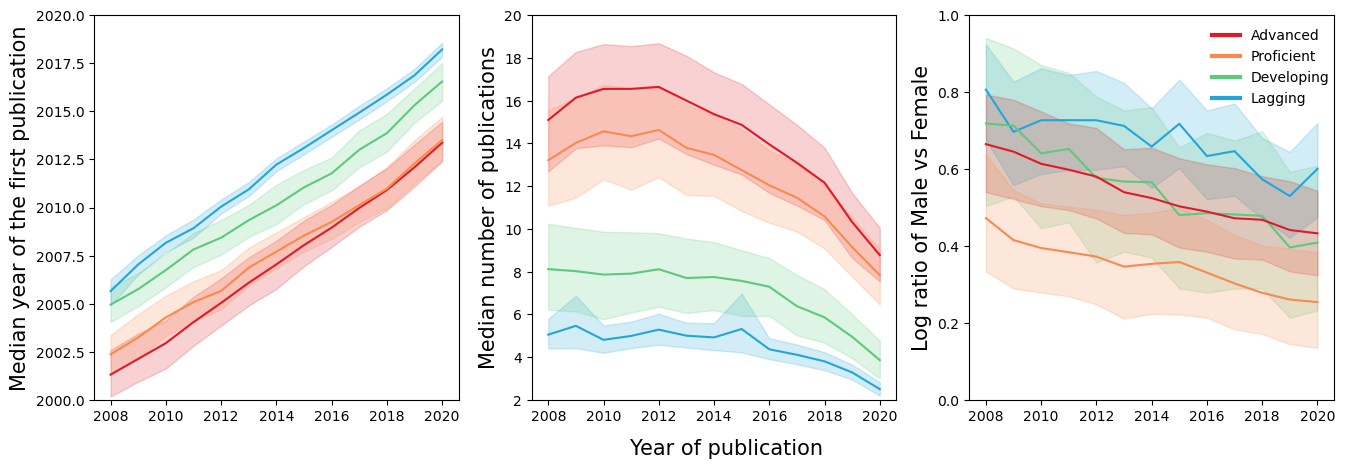

In [16]:
fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(16,5))
colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
labels = ['Advanced', 'Proficient', 'Developing','Lagging']
hue_color=dict(zip(labels,colors))

yfp_df=work_ann.groupby(['Code','ST','year'])['yfp'].median().reset_index()
ax0=plot_line(yfp_df,'yfp',hue_color,'Median year of the first publication',ax[0])
ax0.set_ylim(2000,2020)

npub_df=work_ann.groupby(['Code','ST','year'])['npub'].median().reset_index()
ax1=plot_line(npub_df,'npub',hue_color,'Median number of publications',ax[1])
ax1.set_ylim(2,20)

gender_df=work_ann.groupby(['Code','ST','year','gender']).size().reset_index(name='count')
gender_df=gender_df.pivot(index=['Code','ST','year'],columns='gender',values='count').reset_index()
gender_df['m_f']=gender_df['M']/gender_df['F']
gender_df['m_f']=np.log(gender_df['m_f'])
ax2=plot_line(gender_df,'m_f',hue_color,'Log ratio of Male vs Female',ax[2])
ax2.set_ylim(0,1)

lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
ax2.legend(lines, labels,loc=[0.65,0.75],frameon=False)
fig.text(x=0.46,y=0.00,s="Year of publication",fontsize=15)
plt.savefig(international_workforce_path,bbox_inches='tight')

In [18]:
test = gender_df[gender_df.year==2020]

In [24]:
test[test.ST=='Advanced'].sort_values(by='m_f')

gender,Code,ST,year,F,M,unk,m_f
1111,ISL,Advanced,2020,343.0,376.0,327.0,0.091859
1137,ITA,Advanced,2020,26879.0,29714.0,10865.0,0.100273
760,FIN,Advanced,2020,3834.0,4393.0,1996.0,0.136104
1072,IRL,Advanced,2020,2741.0,3559.0,1198.0,0.261157
2349,TWN,Advanced,2020,6355.0,8446.0,5258.0,0.284451
1742,NOR,Advanced,2020,3935.0,5265.0,2574.0,0.291170
1124,ISR,Advanced,2020,3567.0,4882.0,1839.0,0.313830
1729,NLD,Advanced,2020,10481.0,14459.0,8543.0,0.321753
2173,SWE,Advanced,2020,7413.0,10307.0,3661.0,0.329588
786,FRA,Advanced,2020,21986.0,31053.0,15065.0,0.345290


In [25]:
test[test.ST=='Proficient'].sort_values(by='m_f')

gender,Code,ST,year,F,M,unk,m_f
1007,HRV,Proficient,2020,1638.0,1325.0,594.0,-0.212064
1950,ROU,Proficient,2020,2244.0,1866.0,1034.0,-0.184463
225,BGR,Proficient,2020,929.0,793.0,73.0,-0.158286
1898,PRT,Proficient,2020,5618.0,5295.0,1577.0,-0.059213
1391,LTU,Proficient,2020,887.0,869.0,322.0,-0.020502
2147,SVK,Proficient,2020,1572.0,1630.0,500.0,0.036231
1872,POL,Proficient,2020,7924.0,8259.0,2366.0,0.041407
721,ESP,Proficient,2020,21193.0,24372.0,8007.0,0.139764
2524,ZAF,Proficient,2020,2700.0,3142.0,3112.0,0.151608
734,EST,Proficient,2020,591.0,697.0,355.0,0.164969
